In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT / "src"))
ART = ROOT / "artifacts"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from plotting import series_styles, new_figure

plt.rcParams.update({"figure.dpi": 110, "font.size": 9})

def es(v, d=4):
    """Numero con formato de Colombia: punto de miles y coma decimal."""
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return ""
    if isinstance(v, (int, np.integer)):
        return f"{int(v):,}".replace(",", ".")
    s = f"{float(v):,.{d}f}"
    return s.replace(",", "X").replace(".", ",").replace("X", ".")

def tabla(df, d=4, enteros=()):
    out = df.copy()
    for c in out.columns:
        if c in enteros:
            out[c] = out[c].map(lambda v: es(int(v)) if pd.notna(v) else "")
        elif pd.api.types.is_float_dtype(out[c]):
            out[c] = out[c].map(lambda v: es(v, d))
        elif pd.api.types.is_integer_dtype(out[c]):
            out[c] = out[c].map(es)
    display(out.style.hide(axis="index"))

def figura(ruta, ancho=None):
    display(Image(filename=str(ruta), width=ancho))

# 7. Benchmarking computacional

Este capítulo mide el costo computacional de cada entorno: el tiempo de pared, la memoria pico y las filas por segundo de cada etapa, el escalamiento fuerte y débil de Spark en modo local, el ajuste de la ley de Amdahl, el punto de cruce entre scikit-learn y Spark, la evidencia de la Spark UI y el costo estimado en la nube. Con esto se responde la pregunta P1, a partir de qué volumen PySpark supera a scikit-learn en tiempo de entrenamiento sin degradar la calidad predictiva.

Todas las mediciones se hicieron en la misma máquina, un portátil con Intel Core i5-1235U y 16 GB de RAM. Es un procesador híbrido con 2 núcleos de rendimiento, con 2 hilos cada uno, y 8 núcleos de eficiencia, con 12 hilos en total y un límite de potencia de 15 W. Esta arquitectura condiciona la lectura de todas las curvas de escalamiento. Spark corre en modo local, de modo que el driver y el ejecutor comparten un mismo proceso Java y los "núcleos" de `local[p]` son hilos de ese proceso, no nodos de un clúster.

In [2]:
from scipy.optimize import curve_fit
B = ART / "benchmarking"
strong = pd.read_csv(B / "strong_scaling.csv")
weak = pd.read_csv(B / "weak_scaling.csv")
amd = json.loads((B / "amdahl_fit.json").read_text(encoding="utf-8"))
cross = pd.read_csv(B / "crossover_point.csv")
efec = json.loads((B / "tamanos_efectivos.json").read_text(encoding="utf-8"))
etapas = pd.read_csv(B / "tiempos_por_etapa.csv")
ui = pd.read_csv(B / "spark_ui_stages.csv")
def paneles(titulos, tam=(10, 3.8)):
    fig, axes = plt.subplots(1, len(titulos), figsize=tam)
    for a, t in zip(axes, titulos):
        a.grid(True, color="#d9d9d9", linewidth=0.6); a.set_axisbelow(True); a.set_title(t, fontsize=10)
        for s in ("top", "right"): a.spines[s].set_visible(False)
    return fig, axes

## 7.1 Tiempo, memoria y rendimiento por etapa

Para medir las etapas por separado, ambos entornos leen el mismo archivo Parquet, de 800.847 filas de train y 200.000 de prueba, y entrenan la misma regresión logística afinada; en scikit-learn se mide además el MLP. La memoria pico se obtiene muestreando cada 0,1 s el RSS del proceso Python, en scikit-learn, o del proceso Java, en Spark. En scikit-learn, el target encoding de train es fuera de pliegue, así que el ajuste y la transformación de train ocurren en una sola pasada y se reportan como una etapa. En Spark, la lectura y la transformación incluyen un `cache()` seguido de `count()`, que obliga a materializar los datos, porque Spark evalúa de forma perezosa.

In [3]:
t = etapas.copy()
t["entorno"] = t["entorno"].map({"sklearn": "scikit-learn", "spark": "Spark local[*]"})
tabla(t.rename(columns={"tiempo_s": "tiempo (s)", "filas_por_s": "filas por segundo", "memoria_pico_mb": "memoria pico (MB)"}),
      d=2, enteros=("filas",))

entorno,etapa,filas,tiempo (s),filas por segundo,memoria pico (MB)
scikit-learn,lectura_train,800.847,"0,68","1.169.132,51","721,77"
scikit-learn,preprocesamiento_ajuste_y_transform,800.847,"18,89","42.398,75","1.972,50"
scikit-learn,entrenamiento_sgd,800.847,"10,22","78.348,05","1.091,04"
scikit-learn,entrenamiento_mlp,800.847,"171,11","4.680,36","1.363,14"
scikit-learn,lectura_test,200.000,"0,17","1.166.193,68","1.164,89"
scikit-learn,preprocesamiento_test,200.000,"2,37","84.243,59","1.382,43"
scikit-learn,prediccion_sgd,200.000,"0,02","10.425.626,20","1.167,04"
scikit-learn,prediccion_mlp,200.000,"0,12","1.647.708,41","1.243,33"
Spark local[*],lectura_train,800.847,"10,22","78.336,62","1.465,45"
Spark local[*],preprocesamiento_ajuste,800.847,"11,78","68.006,00","2.542,68"


**Interpretación.** En scikit-learn, la lectura del Parquet de train tarda 0,68 s, unos 1,17 millones de filas por segundo, y la etapa más costosa del preprocesamiento es el ajuste con transformación, 18,9 s y 42.400 filas por segundo, que es también el pico de memoria del proceso, 1.972,5 MB. La regresión logística entrena en 10,2 s (78.300 filas por segundo) y el MLP en 171,1 s (4.700 filas por segundo), y predecir 200.000 filas tarda 0,02 s con la regresión y 0,12 s con el MLP. En Spark, la lectura con caché tarda 10,2 s (78.300 filas por segundo), el preprocesamiento 17,4 s entre ajuste y transformación, el entrenamiento 14,2 s (56.400 filas por segundo) y la predicción 0,18 s; la memoria del proceso Java crece de 1.465 MB a 2.758 MB a lo largo de la sesión.

Así mismo, el patrón de memoria es distinto en cada entorno. En scikit-learn, el pico ocurre en el preprocesamiento, cuando conviven el DataFrame de pandas, las columnas intermedias del target encoding y la matriz dispersa final; después baja, porque Python libera esos objetos. En Spark, la memoria del proceso Java solo crece, porque la JVM reserva el heap a medida que lo necesita y no lo devuelve al sistema, y la caché de los datos y de las variables permanece durante la sesión. El dato que limita la escala en scikit-learn es el pico del preprocesamiento: unos 2,6 KB por fila de train con 800 mil filas, que se usa en la sección 7.4 para estimar hasta dónde llega scikit-learn en 16 GB.

Por lo anterior, conviene comparar los entornos por etapa y no solo por el tiempo de entrenamiento: con este volumen, la diferencia más grande está en la lectura (15 veces más lenta en Spark) y no en el modelo, que en esta corrida tardó 1,4 veces más en Spark. La sección 7.4 muestra que la comparación del ajuste a este tamaño depende del estado de la máquina.

## 7.2 Escalamiento fuerte

El escalamiento fuerte fija el problema, 1.601.694 filas efectivas de train, y varía el número de núcleos de Spark con `local[1]`, `local[2]`, `local[4]`, `local[8]` y `local[12]`. Se mide el ajuste del pipeline de variables y de una regresión logística con 30 iteraciones, sin contar el arranque de la sesión. La aceleración y la eficiencia son

$$S(p) = \frac{T(1)}{T(p)}, \qquad E(p) = \frac{S(p)}{p},$$

y la ley de Amdahl {cite}`amdahl1967validity` supone que una fracción $f$ del trabajo es secuencial y el resto se reparte sin costo entre los $p$ núcleos:

$$S_{\text{Amdahl}}(p) = \frac{1}{f + (1 - f)/p}, \qquad \lim_{p \to \infty} S_{\text{Amdahl}}(p) = \frac{1}{f}.$$

El parámetro $f$ se estima por mínimos cuadrados no lineales sobre los 5 puntos.

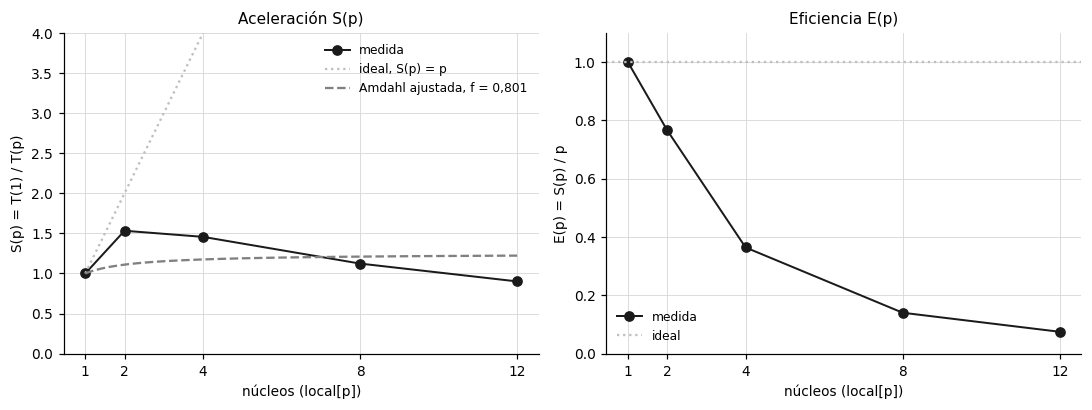

núcleos,tiempo (s),S(p) medida,S Amdahl,residuo
1,"138,040","1,000","1,000","0,000"
2,"90,058","1,533","1,110","0,422"
4,"94,763","1,457","1,175","0,282"
8,"122,859","1,124","1,210","-0,087"
12,"153,180","0,901","1,223","-0,322"


Amdahl: f = 0,8013 (error estándar 0,1361); con solo p = 1 y 2, f = 2/S(2) − 1 = 0,305


In [4]:
p = strong["p_nucleos"].values.astype(float)
f = amd["fraccion_secuencial_f"]
pg = np.linspace(1, 12, 100)
fig, (a1, a2) = paneles(["Aceleración S(p)", "Eficiencia E(p)"])
a1.plot(p, strong["speedup"], color="#1a1a1a", marker="o", linewidth=1.3, label="medida")
a1.plot(pg, pg, color="#bfbfbf", linestyle=":", label="ideal, S(p) = p")
a1.plot(pg, 1 / (f + (1 - f) / pg), color="#808080", linestyle="--", label=f"Amdahl ajustada, f = {es(f, 3)}")
a1.set_xlabel("núcleos (local[p])"); a1.set_ylabel("S(p) = T(1) / T(p)"); a1.set_ylim(0, 4); a1.legend(frameon=False, fontsize=8)
a2.plot(p, strong["eficiencia"], color="#1a1a1a", marker="o", linewidth=1.3, label="medida")
a2.axhline(1, color="#bfbfbf", linestyle=":", label="ideal")
a2.set_xlabel("núcleos (local[p])"); a2.set_ylabel("E(p) = S(p) / p"); a2.set_ylim(0, 1.1); a2.legend(frameon=False, fontsize=8)
for a in (a1, a2): a.set_xticks([1, 2, 4, 8, 12])
plt.tight_layout(); plt.show()
s = strong.copy(); s["S Amdahl"] = 1 / (f + (1 - f) / s["p_nucleos"]); s["residuo"] = s["speedup"] - s["S Amdahl"]
tabla(s.drop(columns=["eficiencia"]).rename(columns={"p_nucleos": "núcleos", "tiempo_s": "tiempo (s)", "speedup": "S(p) medida"}),
      d=3, enteros=("núcleos",))
print(f"Amdahl: f = {es(f, 4)} (error estándar {es(amd['error_estandar_f'], 4)}); con solo p = 1 y 2, f = 2/S(2) − 1 = {es(2 / strong['speedup'].iloc[1] - 1, 3)}")

**Interpretación.** El tiempo baja de 138,0 s con un núcleo a 90,1 s con dos, una aceleración de 1,53 y una eficiencia de 0,77, y desde ahí empeora: 94,8 s con 4 núcleos, 122,9 s con 8 y 153,2 s con 12. Con 12 núcleos, el ajuste tarda más que con uno ($S = 0{,}90$) y la eficiencia cae a 0,075. El ajuste de Amdahl da $f = 0{,}801$, con un error estándar de 0,136, y sus residuos tienen un patrón sistemático: subestima la aceleración en $p = 2$ y $p = 4$ (1,11 y 1,18 frente a 1,53 y 1,46 medidos) y la sobreestima en $p = 8$ y $p = 12$ (1,21 y 1,22 frente a 1,12 y 0,90).

Lo anterior indica que la ley de Amdahl no describe este sistema y que $f = 0{,}80$ no debe leerse como la fracción secuencial real. Amdahl solo admite aceleraciones que crecen o se estabilizan con $p$; una curva que alcanza su máximo en $p = 2$ y luego cae necesita un término de costo que crezca con el número de núcleos, como la coordinación entre tareas, la agregación en árbol de los gradientes de la regresión logística en el driver y la competencia por el ancho de banda de memoria. Con solo los puntos $p = 1$ y $p = 2$, Amdahl daría $f = 2/S(2) - 1 = 0{,}30$, lo que muestra que el valor ajustado depende de qué parte de la curva se use. La arquitectura híbrida explica el máximo en $p = 2$: con dos hilos, las tareas corren en los núcleos de rendimiento; desde cuatro, una parte cae en los de eficiencia, más lentos, y como cada etapa de Spark termina cuando acaba su tarea más lenta, los núcleos rápidos esperan a los lentos. Además, con el límite de 15 W, el procesador baja la frecuencia cuando hay más núcleos activos.

Por tal motivo, se opta por reportar el ajuste de Amdahl como lo pide el enunciado, pero con la advertencia de que su supuesto central no se cumple en esta máquina, y por configurar Spark con pocos núcleos para cargas de este tamaño. El punto óptimo medido es `local[2]`, y no `local[*]`.

## 7.3 Escalamiento débil

El escalamiento débil aumenta el problema en proporción a los núcleos, con unas 800.847 filas efectivas por núcleo, de modo que el tiempo ideal es constante. Se reportan la eficiencia débil $T(1)/T(p)$ y la aceleración escalada de Gustafson {cite}`gustafson1988reevaluating`, $p \cdot T(1)/T(p)$, que mide cuántas veces más trabajo se hace por unidad de tiempo.

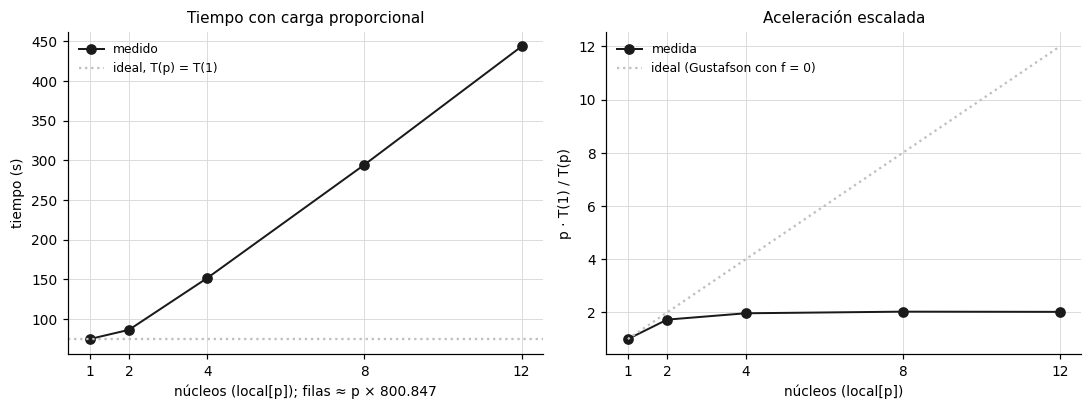

núcleos,tiempo (s),filas efectivas,eficiencia débil T(1)/T(p),filas por segundo
1,"74,719",800.847,"1,000","10.718,147"
2,"86,326",1.601.694,"0,866","18.554,062"
4,"151,752",3.203.388,"0,492","21.109,399"
8,"294,376",6.406.777,"0,254","21.763,961"
12,"443,254",9.610.165,"0,169","21.680,930"


In [5]:
w = weak.copy()
w["filas_efectivas"] = w["p_nucleos"].astype(str).map(efec["weak_scaling_efectivo_aprox"]).astype(int)
t1 = w["tiempo_s"].iloc[0]
w["eficiencia débil T(1)/T(p)"] = t1 / w["tiempo_s"]
w["aceleración escalada p·T(1)/T(p)"] = w["p_nucleos"] * t1 / w["tiempo_s"]
w["filas por segundo"] = w["filas_efectivas"] / w["tiempo_s"]
fig, (a1, a2) = paneles(["Tiempo con carga proporcional", "Aceleración escalada"])
a1.plot(w["p_nucleos"], w["tiempo_s"], color="#1a1a1a", marker="o", linewidth=1.3, label="medido")
a1.axhline(t1, color="#bfbfbf", linestyle=":", label="ideal, T(p) = T(1)")
a1.set_xlabel("núcleos (local[p]); filas ≈ p × 800.847"); a1.set_ylabel("tiempo (s)"); a1.legend(frameon=False, fontsize=8)
a2.plot(w["p_nucleos"], w["aceleración escalada p·T(1)/T(p)"], color="#1a1a1a", marker="o", linewidth=1.3, label="medida")
a2.plot(w["p_nucleos"], w["p_nucleos"], color="#bfbfbf", linestyle=":", label="ideal (Gustafson con f = 0)")
a2.set_xlabel("núcleos (local[p])"); a2.set_ylabel("p · T(1) / T(p)"); a2.legend(frameon=False, fontsize=8)
for a in (a1, a2): a.set_xticks([1, 2, 4, 8, 12])
plt.tight_layout(); plt.show()
tabla(w.drop(columns=["n_filas", "aceleración escalada p·T(1)/T(p)"]).rename(columns={"p_nucleos": "núcleos", "filas_efectivas": "filas efectivas", "tiempo_s": "tiempo (s)"}),
      d=3, enteros=("núcleos", "filas efectivas"))

**Interpretación.** El tiempo pasa de 74,7 s con un núcleo y 800 mil filas a 86,3 s con dos núcleos y 1,6 millones, y después crece casi en proporción a los datos: 151,8 s con 4 núcleos, 294,4 s con 8 y 443,3 s con 12 y 9,6 millones de filas. La eficiencia débil cae de 0,87 con dos núcleos a 0,17 con doce, y la aceleración escalada se estanca en torno a 2: 1,73 con dos núcleos, 1,97 con cuatro, 2,03 con ocho y 2,02 con doce. El rendimiento pasa de unas 10.700 filas por segundo con un núcleo a unas 21.700 con doce.

Es decir, a partir de dos núcleos, agregar hilos de Spark en esta máquina no aumenta el rendimiento: con 12 núcleos se procesa el doble de filas por segundo que con uno, no doce veces más. El escalamiento débil confirma la lectura del escalamiento fuerte con otra métrica. El techo práctico de paralelismo es de unos 2 núcleos efectivos, igual al número de núcleos de rendimiento, y lo que se agrega después no compensa la coordinación ni la lentitud de los núcleos de eficiencia.

En consecuencia, se decide no extrapolar estos resultados a un clúster. En un clúster real, cada ejecutor tiene sus propios núcleos, memoria y ancho de banda, y el escalamiento depende de la red y del shuffle, no de la competencia dentro de un mismo procesador. Lo que sí se puede afirmar es que, en una sola máquina como esta, Spark no convierte núcleos adicionales en velocidad.

## 7.4 Punto de cruce

El punto de cruce se busca comparando el tiempo de ajuste de la regresión logística en ambos entornos, con la misma muestra para los dos en cada tamaño y en la misma sesión: los tres tamaños efectivos de scikit-learn (80.085, 800.847 y 1.601.694 filas) y el doble del mayor (3.203.388). En ambos entornos se mide solo el ajuste del modelo sobre variables ya calculadas; en Spark, las variables se materializan en caché antes de medir y los datos entran como Parquet, igual que en la sección 7.1. scikit-learn se mide con las 5 semillas y Spark con 3 repeticiones del ajuste, porque L-BFGS es determinista y las repeticiones solo miden la variación del tiempo. Antes de correr scikit-learn se verifica que la memoria disponible alcance para su pico de preprocesamiento, estimado en 2,6 KB por fila (sección 7.1) con un margen del 30 %; si no alcanza, ese tamaño se mide solo en Spark.

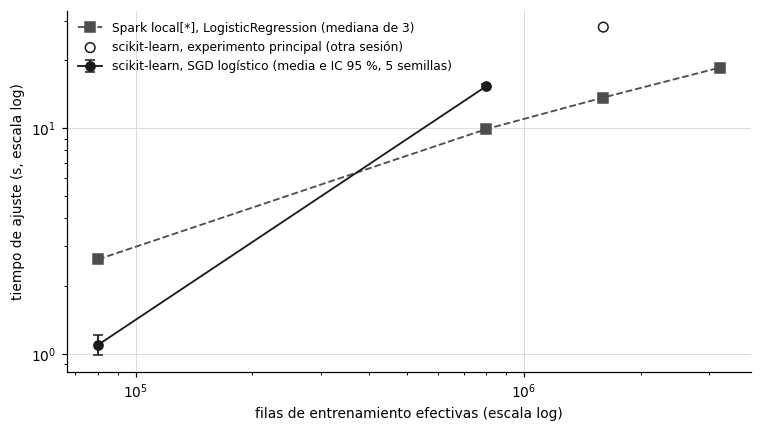

filas efectivas,scikit-learn (s),DE scikit-learn,épocas SGD,Spark (s),DE Spark,iteraciones L-BFGS,Spark / scikit-learn,RAM estimada scikit-learn (MB),RAM disponible (MB)
80.085,"1,10","0,09","38,60","2,62","2,62",38,"2,39","258,15","3.936,70"
800.847,"15,38","0,33","37,40","9,92","0,62",37,"0,65","2.581,47","3.359,84"
1.601.694,,,,"13,69","0,55",37,,"5.162,93","2.836,45"
3.203.388,,,,"18,60","1,43",37,,"10.325,86","2.010,86"


Exponente empírico t ∝ n^b: scikit-learn b = 1,15, Spark b = 0,54


In [6]:
fig, ax = new_figure((7, 4))
st = series_styles(2)
ax.errorbar(cross["n_filas_efectivas"], cross["tiempo_sklearn_sgd_s"], yerr=2.776 * cross["de_sklearn_sgd_s"] / np.sqrt(5),
            label="scikit-learn, SGD logístico (media e IC 95 %, 5 semillas)", color=st[0]["color"], linestyle=st[0]["linestyle"],
            marker=st[0]["marker"], capsize=3, linewidth=1.2)
ax.plot(cross["n_filas_efectivas"], cross["tiempo_spark_lr_s"], label="Spark local[*], LogisticRegression (mediana de 3)", color=st[1]["color"],
        linestyle=st[1]["linestyle"], marker=st[1]["marker"], linewidth=1.2)
ref = pd.read_csv(ART / "sklearn" / "runs.csv").query("model == 'sgd'").groupby("tier")["fit_time_s"].mean()
ax.scatter([1601694], [ref.loc[2000000]], marker="o", facecolor="none", edgecolor="#1a1a1a", s=40, zorder=3,
           label="scikit-learn, experimento principal (otra sesión)")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("filas de entrenamiento efectivas (escala log)"); ax.set_ylabel("tiempo de ajuste (s, escala log)")
ax.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()
c = cross[["n_filas_efectivas", "tiempo_sklearn_sgd_s", "de_sklearn_sgd_s", "iteraciones_sklearn", "tiempo_spark_lr_s", "de_spark_lr_s",
           "iteraciones_spark", "razon_spark_sobre_sklearn", "memoria_necesaria_sklearn_mb", "memoria_disponible_mb"]]
tabla(c.rename(columns={"n_filas_efectivas": "filas efectivas", "tiempo_sklearn_sgd_s": "scikit-learn (s)", "de_sklearn_sgd_s": "DE scikit-learn",
                        "iteraciones_sklearn": "épocas SGD", "tiempo_spark_lr_s": "Spark (s)", "de_spark_lr_s": "DE Spark",
                        "iteraciones_spark": "iteraciones L-BFGS", "razon_spark_sobre_sklearn": "Spark / scikit-learn",
                        "memoria_necesaria_sklearn_mb": "RAM estimada scikit-learn (MB)", "memoria_disponible_mb": "RAM disponible (MB)"}),
      d=2, enteros=("filas efectivas", "iteraciones L-BFGS"))
ok = cross.dropna(subset=["tiempo_sklearn_sgd_s"])
b_sk = np.polyfit(np.log(ok["n_filas_efectivas"]), np.log(ok["tiempo_sklearn_sgd_s"]), 1)[0]
b_sp = np.polyfit(np.log(cross["n_filas_efectivas"]), np.log(cross["tiempo_spark_lr_s"]), 1)[0]
print(f"Exponente empírico t ∝ n^b: scikit-learn b = {es(b_sk, 2)}, Spark b = {es(b_sp, 2)}")

**Interpretación.** Con 80.085 filas, scikit-learn ajusta la regresión logística en 1,10 s (DE de 0,09 s entre semillas) y Spark en 2,62 s, 2,4 veces más. Con 800.847 filas, scikit-learn tarda 15,38 s (DE de 0,33 s) y Spark 9,92 s, de modo que Spark ya es 1,55 veces más rápido en el ajuste. Con 1.601.694 y 3.203.388 filas, Spark tarda 13,69 s y 18,60 s, y scikit-learn no se pudo medir: la memoria disponible en ese momento, 2.836 MB y 2.011 MB con el navegador y el editor abiertos, no alcanzaba para el pico estimado de su preprocesamiento, de 5.163 MB y 10.326 MB. Como referencia, en el experimento principal, en otra sesión, scikit-learn ajustó 1.601.694 filas en 28,1 s en promedio. Los exponentes empíricos muestran el cambio de régimen: el tiempo de Spark crece de forma muy sublineal con el volumen ($b = 0{,}54$), porque a 80 mil filas lo domina el costo fijo de cada iteración, y el de scikit-learn crece de forma aproximadamente lineal ($b = 1{,}15$ entre los dos tamaños medidos y 0,94 en el experimento principal, sección 4.5).

Hay que tener en cuenta que la medición del punto de cruce tiene una incertidumbre grande en esta máquina. El benchmarking por etapas de la sección 7.1 usó exactamente la misma muestra de 800.847 filas y la misma semilla, y allí scikit-learn ajustó en 10,2 s y Spark en 14,2 s, el orden inverso. Como el SGD con la misma semilla y los mismos datos hace el mismo número de épocas, la diferencia entre 10,2 s y 15,4 s se debe al estado de la máquina, a la memoria ocupada por otras aplicaciones y a la frecuencia del procesador, y no al algoritmo. Lo anterior indica que, alrededor de 800 mil filas, los dos entornos están empatados dentro de la variación entre corridas de un portátil, que es de hasta un 50 %, y que el punto de cruce del tiempo de ajuste está entre unas 400 mil y 1 millón de filas, sin poder fijarse con más precisión. Lo que sí es robusto es la tendencia: por debajo de ese rango scikit-learn gana con claridad, por encima Spark escala mejor, y desde 1,6 millones de filas scikit-learn deja de caber en la memoria disponible de esta máquina.

Por lo anterior, conviene distinguir dos puntos de cruce. En el tiempo de ajuste del modelo, Spark empieza a ganar entre unas 400 mil y 1 millón de filas. En el flujo completo, que incluye leer, poner en caché y preprocesar, Spark seguía siendo 1,46 veces más lento con 800 mil filas (sección 9.2), así que el cruce real ocurre a un volumen mayor, que en esta máquina coincide con el límite de memoria de scikit-learn. Por eso, el criterio práctico para elegir Spark aquí no es la velocidad, sino si los datos caben en memoria.

## 7.5 Evidencia de la Spark UI

La Spark UI se habilitó solo en `src/stage_benchmark.py`, y sus métricas por stage se leyeron de su API REST antes de cerrar la sesión. Para cada stage se reportan los datos de entrada, el shuffle leído y escrito, el *spill* a disco y el sesgo entre tareas, medido como la razón entre la tarea más lenta y la mediana.

In [7]:
u = ui.copy()
u["nombre"] = u["nombre"].str.slice(0, 45)
tabla(u[["stage_id", "nombre", "num_tareas", "input_mb", "shuffle_lectura_mb", "shuffle_escritura_mb", "spill_disco_mb",
         "tiempo_tarea_mediana_ms", "tiempo_tarea_max_ms", "sesgo_max_sobre_mediana"]].rename(columns={
    "stage_id": "stage", "num_tareas": "tareas", "input_mb": "entrada (MB)", "shuffle_lectura_mb": "shuffle lectura (MB)",
    "shuffle_escritura_mb": "shuffle escritura (MB)", "spill_disco_mb": "spill a disco (MB)", "tiempo_tarea_mediana_ms": "tarea mediana (ms)",
    "tiempo_tarea_max_ms": "tarea máxima (ms)", "sesgo_max_sobre_mediana": "máx./mediana"}), d=2, enteros=("stage", "tareas"))
print(f"Totales: {len(u)} stages; shuffle escrito {es(u['shuffle_escritura_mb'].sum(), 2)} MB; spill a disco {es(u['spill_disco_mb'].sum(), 2)} MB; "
      f"spill en memoria {es(u['spill_memoria_mb'].sum(), 2)} MB")

stage,nombre,tareas,entrada (MB),shuffle lectura (MB),shuffle escritura (MB),spill a disco (MB),tarea mediana (ms),tarea máxima (ms),máx./mediana
0,parquet at NativeMethodAccessorImpl.java:0,1,"0,00","0,00","0,00","0,00","477,00","477,00","1,00"
1,count at NativeMethodAccessorImpl.java:0,10,"39,21","0,00","0,00","0,00","4.294,00","4.313,00","1,00"
2,count at NativeMethodAccessorImpl.java:0,10,"51,77","0,00","0,00","0,00","266,00","296,00","1,11"
4,count at NativeMethodAccessorImpl.java:0,1,"0,00","0,00","0,00","0,00","140,00","140,00","1,00"
5,collect at StringIndexer.scala:204,10,"51,77","0,00","0,00","0,00","2.261,00","2.295,00","1,02"
7,collect at StringIndexer.scala:204,1,"0,00","0,00","0,00","0,00","149,00","149,00","1,00"
8,collect at StringIndexer.scala:204,10,"51,77","0,00","0,00","0,00","287,00","334,00","1,16"
10,collect at StringIndexer.scala:204,1,"0,00","0,00","0,00","0,00","95,00","95,00","1,00"
11,collect at StringIndexer.scala:204,10,"51,77","0,00","0,00","0,00","170,00","213,00","1,25"
13,collect at StringIndexer.scala:204,1,"0,00","0,00","0,00","0,00","79,00","79,00","1,00"


Totales: 114 stages; shuffle escrito 9,96 MB; spill a disco 0,00 MB; spill en memoria 0,00 MB


**Interpretación.** La sesión ejecutó 114 stages. No hubo *spill* ni a disco ni en memoria, y el shuffle total fue de 10 MB, casi todo en los 84 stages de `treeAggregate` de la función de pérdida de la regresión logística, que agregan el gradiente de cada partición hacia el driver en cada evaluación de L-BFGS. El sesgo entre tareas es bajo: la mediana de la razón entre la tarea más lenta y la tarea mediana es 1,01, y en los stages pesados, como la lectura a caché, el cálculo del escalador y la materialización de las variables, con tareas de 2,3 a 4,6 s, no pasa de 1,03. El valor máximo, 1,88, corresponde a un stage de agregación cuyas tareas duran entre 41 y 77 ms, donde la diferencia es ruido de planificación.

Lo anterior indica que la carga no está limitada por disco, por memoria ni por un desbalance de datos entre particiones, sino por cómputo y por coordinación. La regresión logística ejecuta unas 40 rondas de agregación, cada una con su planificación de tareas y su paso por el driver, y ese costo fijo por ronda es el que se repite en el escalamiento fuerte. Como las tareas de un mismo stage duran casi lo mismo, la caída de la aceleración con más núcleos no se debe a una tarea rezagada, sino a que todas las tareas se vuelven más lentas cuando corren muchas a la vez. Esto es compatible con el límite de potencia del procesador, con la mezcla de núcleos de rendimiento y de eficiencia y con la competencia por el ancho de banda de memoria.

Por esta razón, lo indicado para cargas de este tamaño en una sola máquina es reducir el número de rondas, por ejemplo con menos iteraciones o con una tolerancia de convergencia más laxa, y no agregar núcleos. El *spill* y el sesgo, que son las causas típicas de lentitud en Spark, no son el problema aquí.

## 7.6 Costo estimado en la nube

Como referencia de precio se toma una instancia AWS EC2 `m6i.2xlarge` bajo demanda (8 vCPU y 32 GiB de memoria, Linux, región us-east-1), con una tarifa de 0,384 USD por hora. La tarifa se tomó de dos calculadoras de terceros, [Holori](https://calculator.holori.com/aws/ec2/m6i.2xlarge) y [DoiT](https://www.doit.com/compute/spot/us-east-1/m6i.2xlarge), consultadas el 7 de noviembre de 2026, y debe confirmarse en la lista de precios oficial de AWS antes de usarla para presupuestar. El costo de cada corrida se estima como su tiempo de pared medido en esta máquina multiplicado por la tarifa.

In [8]:
PRECIO_H = 0.384  # USD por hora, AWS EC2 m6i.2xlarge bajo demanda, Linux, us-east-1 (fuentes de terceros, consultadas el 07/11/2026)
sk = pd.read_csv(ART / "sklearn" / "runs.csv").query("tier == 2000000")
sp = pd.read_csv(ART / "spark" / "runs.csv")
filas = []
for m, nom in (("sgd", "SGD"), ("histgb", "HistGB"), ("mlp", "MLP")):
    s = sk[sk["model"] == m]["fit_time_s"].mean() + sk[sk["model"] == m]["predict_time_s"].mean()
    filas.append({"entorno": "scikit-learn (1,6 M filas)", "modelo": nom, "segundos por corrida": s})
for m, nom in (("lr", "LR (32,4 M filas)"), ("gbt", "GBT (1 M filas)"), ("mlp", "MLP (300 mil filas)")):
    g = sp[sp["model"] == m]
    s = (g["feature_fit_time_s"] + g["fit_time_s"] + g["predict_time_s"]).mean()
    filas.append({"entorno": "Spark local", "modelo": nom, "segundos por corrida": s})
c = pd.DataFrame(filas)
c["USD por corrida"] = c["segundos por corrida"] / 3600 * PRECIO_H
c["USD por 5 semillas"] = 5 * c["USD por corrida"]
tabla(c, d=3)

entorno,modelo,segundos por corrida,USD por corrida,USD por 5 semillas
"scikit-learn (1,6 M filas)",SGD,"28,139","0,003","0,015"
"scikit-learn (1,6 M filas)",HistGB,"15,373","0,002","0,008"
"scikit-learn (1,6 M filas)",MLP,"330,715","0,035","0,176"
Spark local,"LR (32,4 M filas)","708,095","0,076","0,378"
Spark local,GBT (1 M filas),"429,028","0,046","0,229"
Spark local,MLP (300 mil filas),"2.034,157","0,217","1,085"


**Interpretación.** Con la tarifa de referencia, una corrida cuesta entre 0,002 y 0,035 USD en scikit-learn y entre 0,046 y 0,217 USD en Spark. La corrida más cara es la del MLP de Spark, unos 2.034 s entre preprocesamiento, entrenamiento y predicción, y la de la regresión logística de Spark, que procesa el train completo, cuesta 0,076 USD. Las 5 semillas del MLP de Spark cuestan unos 1,09 USD y las del MLP de scikit-learn unos 0,18 USD.

Hay que tener en cuenta tres límites de esta estimación. El primero es que los tiempos se midieron en un portátil de 12 hilos con límite de potencia de 15 W, no en la instancia de referencia, que tiene 8 vCPU de servidor; el costo real puede ser mayor o menor, y solo el orden de magnitud es confiable. El segundo es que la tarifa corresponde a una máquina virtual sin el recargo de un servicio administrado de Spark, como Amazon EMR o Databricks, que no se consultó y no se incluye. El tercero es que un clúster real tendría varios nodos, y su costo crecería con el número de nodos aunque el tiempo bajara.

En síntesis, el costo de cómputo de este proyecto es de centavos de dólar por corrida, y la diferencia entre entornos no está en el precio de la máquina, sino en que Spark tarda más para el mismo resultado a estos volúmenes. Con base en esto, se propone presupuestar la migración a un clúster solo cuando el volumen supere la memoria de una máquina, que es el escenario donde Spark aporta algo que scikit-learn no puede hacer.